In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("homework_4_files/course_lead_scoring_2026.csv")

In [4]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


## Data preparation

In [5]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [6]:
for col in categorical:
    print(col)
    print(df[col].isna().sum())

lead_source
148
industry
240
employment_status
194
location
208


In [7]:
for col in categorical:
    df[col] = df[col].fillna('NA')

In [8]:
for col in numerical:
    print(col)
    print(df[col].isna().sum())

annual_income
369
number_of_courses_viewed
0
interaction_count
0
lead_score
35


In [9]:
for col in numerical:
    df[col] = df[col].fillna(0.0)

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [12]:
y_full_train = df_full_train["converted"]
y_test = df_test["converted"]
y_train = df_train["converted"]
y_val = df_val["converted"]

In [13]:
del df_full_train["converted"]
del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

## Question 1

In [14]:
from sklearn.metrics import roc_auc_score

In [15]:
df_train[numerical]

,annual_income,number_of_courses_viewed,interaction_count,lead_score
4740,80198.0,5,9,0.91
1452,50548.0,2,5,0.48
2846,76300.0,0,3,0.42
4670,80371.0,2,6,0.49
168,73567.0,2,4,0.48
...,...,...,...,...
253,84573.0,2,3,0.37
1366,85051.0,1,3,0.56
753,21561.0,0,1,0.17
4990,31691.0,3,5,0.49


In [16]:
for col in numerical:
    print(col)
    print(roc_auc_score(y_train, df_train[col]))
    print()

annual_income
0.6081977776250831

number_of_courses_viewed
0.7229894623989618

interaction_count
0.7649203047563227

lead_score
0.7882254810906102



lead_score has the highest AUC. <br>Note that none of the scores were less than 0.5

## Question 2

In [17]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [18]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [19]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.651)

In [20]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

0.732

## Question 3 (update, calculating tpr and fpr in place of <br>precision and recall)

In [21]:
scores = []

# thresholds = np.linspace(0, 1, 100)

for t100 in range(0, 101, 1):
    t = t100 / 100
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [22]:
scores

[(0.0, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.01, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.02, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.03, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.04, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.05, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.06, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.07, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.08, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.09, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.1, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.11, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.12, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.13, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.14, np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (0.15, np.int64(586), np.i

In [23]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [24]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,586,414,0,0,1.000000,1.0
1,0.01,586,414,0,0,1.000000,1.0
2,0.02,586,414,0,0,1.000000,1.0
3,0.03,586,414,0,0,1.000000,1.0
4,0.04,586,414,0,0,1.000000,1.0
...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,0.001706,0.0
97,0.97,0,0,586,414,0.000000,0.0
98,0.98,0,0,586,414,0.000000,0.0
99,0.99,0,0,586,414,0.000000,0.0


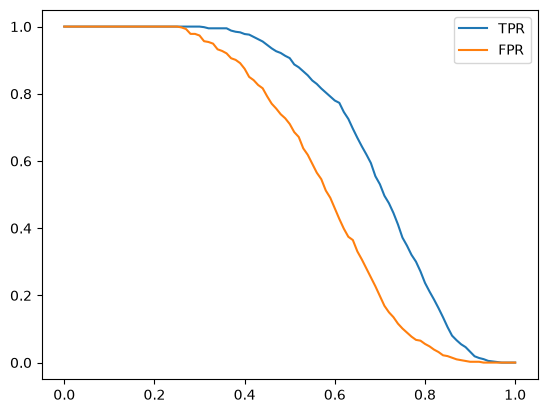

In [25]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [26]:
thresholds = [0.43, 0.63, 0.73, 0.83]

for t in thresholds:
    df_temp = df_scores.loc[df_scores["threshold"] == t]
    df_temp["abs_diff"] = abs(df_temp["tpr"] - df_temp["fpr"])
    display(df_temp)

,threshold,tp,fp,fn,tn,tpr,fpr,abs_diff
43,0.43,564,342,22,72,0.962457,0.826087,0.13637


,threshold,tp,fp,fn,tn,tpr,fpr,abs_diff
63,0.63,425,155,161,259,0.725256,0.374396,0.35086


,threshold,tp,fp,fn,tn,tpr,fpr,abs_diff
73,0.73,261,56,325,358,0.445392,0.135266,0.310127


,threshold,tp,fp,fn,tn,tpr,fpr,abs_diff
83,0.83,95,13,491,401,0.162116,0.031401,0.130715


0.83 threshold has the smallest absolute difference.

# Question 4

In [30]:
f1_scores = []

# thresholds = np.linspace(0, 1, 100)

for t100 in range(0, 101, 1):
    t = t100 / 100
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    f1 = 2 * precision * recall / (precision + recall)
    
    f1_scores.append((t, f1))

/tmp/ipykernel_2915/3740996066.py:19: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


In [31]:
f1_columns = ['threshold', 'f1']
df_f1_scores = pd.DataFrame(f1_scores, columns=f1_columns)

In [35]:
df_f1_scores.loc[df_f1_scores['threshold'].isin([0.21, 0.41, 0.61, 0.81])]

,threshold,f1
21,0.21,0.738966
41,0.41,0.757616
61,0.61,0.745066
81,0.81,0.339726


Maximal at threshold 0.41

# Question 5

In [38]:
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70
...,...,...,...,...,...,...,...,...
2895,paid_ads,manufacturing,NA,north_america,66121.0,1,1,0.20
2763,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69
905,NA,manufacturing,NA,NA,49820.0,2,3,0.44
3980,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50


In [37]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [ ]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))